In [1]:
import pandas as pd
from sklearn.ensemble import IsolationForest

# Load pre-built dataset
df = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")

# Feature engineering
df["DigitRatio"] = df["NoOfDegitsInURL"] / (df["NoOfLettersInURL"] + 1)
df["SpecialRatio"] = df["NoOfOtherSpecialCharsInURL"] / (df["URLLength"] + 1)

# Select features
features = [
    "URLLength", "DomainLength", "NoOfSubDomain",
    "NoOfDegitsInURL", "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL", "IsDomainIP", "IsHTTPS",
    "HasObfuscation", "NoOfURLRedirect",
    "DigitRatio", "SpecialRatio"
]

X = df[features].fillna(0)

# Isolation Forest
model = IsolationForest(contamination=0.05, random_state=42)
df["Anomaly"] = model.fit_predict(X)

# Output
print("Total URLs:", len(df))
print("Normal URLs:", (df["Anomaly"] == 1).sum())
print("Abnormal URLs:", (df["Anomaly"] == -1).sum())

print("\nAbnormal URL Samples:")
print(df[df["Anomaly"] == -1][["URL", "Anomaly"]].head(10))

Total URLs: 235795
Normal URLs: 224005
Abnormal URLs: 11790

Abnormal URL Samples:
                                                   URL  Anomaly
31   https://ipfs.io/ipfs/qmrvvyr84esa2assw9vvwupqj...       -1
32            http://att-103731-107123.weeblysite.com/       -1
45   https://pontosapontamentolu.com/gclid/=/c/?gcl...       -1
77   https://s3.amazonaws.com/appforest_uf/f1678949...       -1
92   https://a04854e8-0cca-4b74-80e6-aacb14a4a5f7.i...       -1
104     https://helpadcase1002405739503874569.web.app/       -1
121  https://www.dlrect-smtb.jp.ap1.ib.commetryx.co...       -1
123   http://www.b7a3a060b75c7dcba9c1078d4ead51f0dc.ws       -1
125                              http://198.98.58.123/       -1
156   http://www.l3a40b16a45b1120615b5d1cc655d7da4a.ws       -1


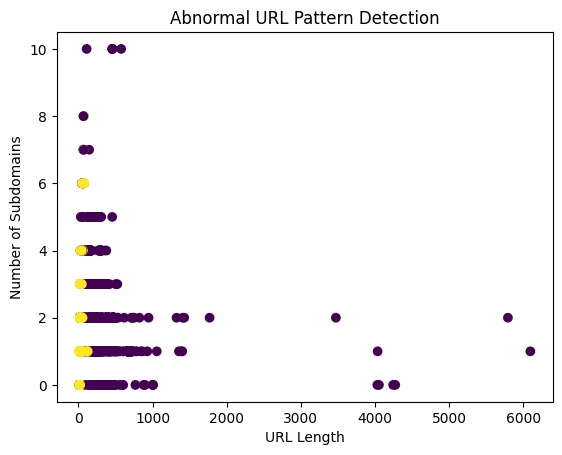

In [2]:
import matplotlib.pyplot as plt

plt.scatter(
    df["URLLength"],
    df["NoOfSubDomain"],
    c=df["Anomaly"]
)

plt.xlabel("URL Length")
plt.ylabel("Number of Subdomains")
plt.title("Abnormal URL Pattern Detection")
plt.show()